In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.pipeline import Pipeline

In [11]:
path_db = '../db/filmes.db'

engine = create_engine(f'sqlite:///{path_db}')

In [12]:
df = pd.read_sql('SELECT * from filmes', con=engine)
df

,id,title,original_title,original_language,overview,budget,revenue,runtime,release_date,genres,popularity,vote_average,vote_count,num_genres,release_year
0,411405,Small Crimes,Small Crimes,en,"A disgraced former cop, fresh off a six-year p...",8.201666e+06,4.243626e+06,95.0,2017-04-28 00:00:00.000000,"['Drama', 'Comedy', 'Thriller', 'Crime']",7.219022,5.8,55.0,4,2017.0
1,42492,Up the Sandbox,Up the Sandbox,en,"A young wife and mother, bored with day-to-day...",3.543621e+05,2.978317e+06,97.0,1972-12-21 00:00:00.000000,"['Drama', 'Comedy']",0.138450,7.3,2.0,2,1972.0
2,12143,Bad Lieutenant,Bad Lieutenant,en,"While investigating a young nun's rape, a corr...",1.000000e+06,2.019469e+06,96.0,1992-09-16 00:00:00.000000,"['Crime', 'Drama']",6.417037,6.9,162.0,2,1992.0
3,9976,Satan's Little Helper,Satan's Little Helper,en,A naïve young boy unknowingly becomes the pawn...,1.890390e+06,1.710526e+06,100.0,2004-01-01 00:00:00.000000,"['Horror', 'Romance', 'Comedy']",2.233189,5.0,42.0,3,2004.0
4,46761,Sitcom,Sitcom,fr,The adventures of an upper-class suburban fami...,8.550376e+05,2.725346e+06,80.0,1998-05-27 00:00:00.000000,"['Comedy', 'Drama', 'Thriller']",1.800582,6.4,27.0,3,1998.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4993,3093,Basic Instinct 2,Basic Instinct 2,en,Novelist Catherine Tramell is once again in tr...,7.000000e+07,3.862948e+07,114.0,2006-03-29 00:00:00.000000,"['Crime', 'Mystery', 'Thriller']",15.321902,4.6,183.0,3,2006.0
4994,246127,Every Thing Will Be Fine,Every Thing Will Be Fine,en,"One day, driving aimlessly around the outskirt...",9.853274e+06,8.034000e+03,118.0,2015-04-02 00:00:00.000000,['Drama'],5.723103,5.3,79.0,1,2015.0
4995,9803,Seven Dwarfs,7 Zwerge - Männer allein im Wald,de,The Seven Dwarves live deep within a female-fr...,9.674091e+06,1.694475e+06,95.0,2004-10-28 00:00:00.000000,['Comedy'],4.582736,5.2,70.0,1,2004.0
4996,336970,True Siblings,Syskonsalt,sv,"The siblings Linus, 19-years-old, who are taki...",1.060106e+06,4.436564e+06,58.0,2000-09-13 00:00:00.000000,"['Drama', 'TV Movie']",2.364355,8.0,2.0,2,2000.0


In [13]:
features = ['budget', 'popularity', 'vote_average']

In [14]:
def model_k_means(df, features):
    
    X = df[features]
    
    pipeline_k_means = Pipeline([('scaler', StandardScaler()), ('k_means', KMeans(n_clusters=2, random_state=42))])
    
    pipeline_k_means.fit(X)
    
    df['clusters'] = pipeline_k_means['k_means'].labels_
    
    sns.pairplot(df, hue='clusters', vars=features, palette='tab10')
    plt.show()
    
    scores = []
    range_n = range(2, 10)
    
    for k in range_n:
        
        pipeline_k_means.set_params(k_means__n_clusters=k)
        labels = pipeline_k_means.fit_predict(X)
        score = silhouette_score(X, labels)
        scores.append(score)
    
    plt.plot(range_n, scores, marker='o')
    plt.xlabel('Número de Clusters (k)')
    plt.ylabel('Silhouette score')
    plt.title('Silhouette score para diferentes k')
    plt.show()
    
    return scores

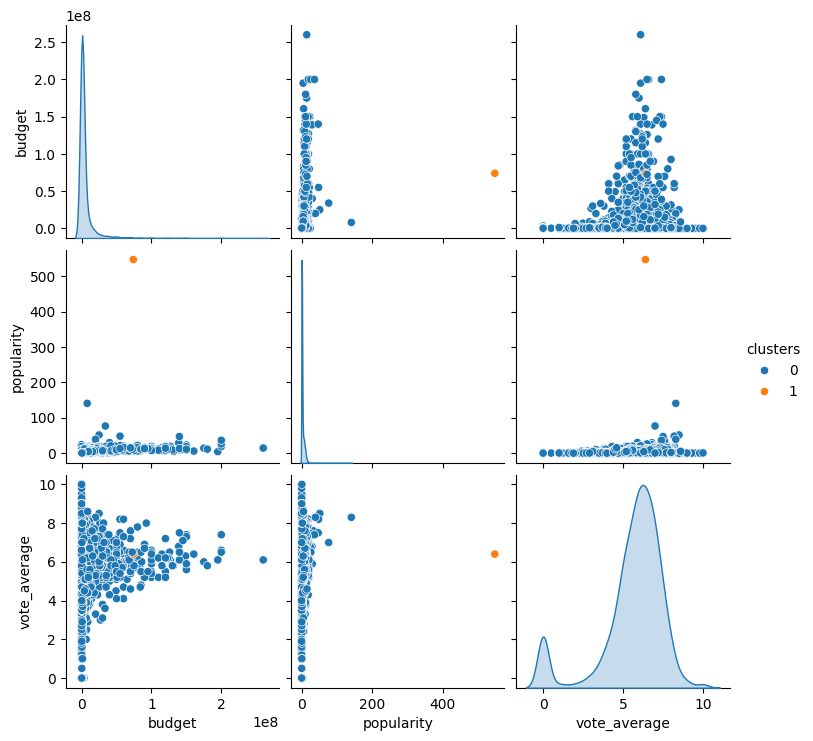

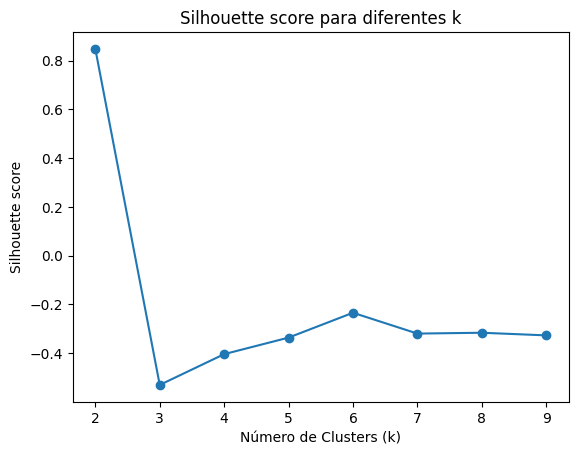

[0.8484903087620315,
 -0.5308841064390287,
 -0.40454241184888895,
 -0.33666499909980485,
 -0.23461877473610335,
 -0.3201267386369199,
 -0.31667612295844205,
 -0.3275125816577675]

In [15]:
modelo_k_means = model_k_means(df, features)
modelo_k_means

Como o maior silhoutte score é o número ideal de clusters, temos que para `k=2` é a situação ideal para essas features com silhoutte score de aproximadamente `0.85`.

Na matriz de dispersão temos que cada ponto é um regitro (filme) e cada cor representa um cluter (azul e laranja). O cluster na cor azul nos diz que grande maioria dos filmes possuem orçamento baixo, popularidade baixa e média de votos variando de 4 a 7 representando os filmes comuns do dataset que não possuem muita fama. Já uma pequena quantidade, no cluster laranja, temos filmes exepcionais com altos orçamento e popularidade alta com grandes indícios de serem outliers pois aparecem bem afastados dos demais, exatamente como o k-means deve capturar quando existem outliers. O resultado é consistente com silhouette alto.  